In [1]:
import os
from scipy import stats
from collections import Counter

In [2]:
# Gene Lists
pathway1=['BCAR1', 'CRK', 'CTRC', 'CTSG', 'DOCK1', 'EGFR', 'ELANE', 'FGA', 'FGB', 'FGG', 'FN1', 'FPR1', 'FPR2', 
          'FPR3', 'GPLD1', 'HGF', 'ITGA3', 'ITGA5', 'ITGAM', 'ITGAV', 'ITGB1', 'ITGB2', 'ITGB3', 'ITGB5', 'KLK4',
          'LRP1', 'MMP12', 'MMP13', 'MMP3', 'MMP9', 'NCL', 'PDGFD', 'PDGFRB', 'PLAU', 'PLAUR', 'PLG', 'RAC1', 
          'SERPINE1', 'SRC', 'TGFB1', 'VLDLR', 'VTN']

pathway2=['ARHGEF11', 'ARHGEF12', 'CDC42', 'ERBB2', 'LIMK1', 'LIMK2', 'MYH10', 'MYH11', 'MYH14', 'MYH9', 'MYL12B', 
          'MYL6', 'MYL9', 'PLXNB1', 'RAC1', 'RAC2', 'RHOA', 'RHOB', 'RHOC', 'RHOG', 'RND1', 'ROCK1', 'ROCK2', 'SEMA4D']

pathway3=['AKT1', 'B2M', 'BCL10', 'CARD11', 'CBL', 'CD247', 'CD28', 'CD3D', 'CD3E', 'CD3G', 'CD80', 'CD86', 'CD8A', 'CD8B',
          'CHUK', 'CSK', 'FYN', 'GRAP2', 'GRB2', 'HLA-A', 'HRAS', 'IKBKB', 'IKBKG', 'LAT', 'LCK', 'LCP2', 'MALT1', 'MAP3K14',
          'MAP3K8', 'NRAS', 'ORAI1', 'PAG1', 'PDPK1', 'PLCG1', 'PRF1', 'PRKCA', 'PRKCB', 'PRKCE', 'PRKCQ', 'PTPN6', 'PTPRC', 
          'RAP1A', 'RASGRP1', 'RASGRP2', 'RASSF5', 'SOS1', 'STIM1', 'TRAF6', 'TRPV6', 'VAV1', 'ZAP70']

pathway4=['BCL2', 'BCL2L1', 'CCNA2', 'CCND2', 'CCND3', 'CDK6', 'ELF1', 'FASLG', 'FOXP3', 'GAB2', 'GRB2', 'IL2', 'IL2RA',
          'IL2RB', 'IL2RG', 'IL4', 'JAK1', 'JAK3', 'LCK', 'LTA', 'MYC', 'PIK3CA', 'PIK3R1', 'PRF1', 'PTPN11', 'SHC1', 
          'SOS1', 'SP1', 'STAT5A', 'STAT5B']

pathway5=['AKT1', 'AKT1S1', 'AKT2', 'AKT3', 'BAD', 'BTC', 'CASP9', 'CD19', 'CD28', 'CD80',
          'CD86', 'CDKN1A', 'CDKN1B', 'CHUK', 'CREB1', 'EGF', 'EGFR', 'ERBB2', 'ERBB3', 'ERBB4', 'EREG', 'FGF1', 'FGF10', 
          'FGF16', 'FGF17', 'FGF18', 'FGF19', 'FGF2', 'FGF20', 'FGF22', 'FGF23', 'FGF3','FGF4', 'FGF5', 'FGF6', 'FGF7', 
          'FGF8', 'FGF9', 'FGFR1', 'FGFR2', 'FGFR3', 'FGFR4', 'FOXO1', 'FOXO3', 'FOXO4', 'FRS2', 'FYN', 'GAB1', 'GRB2', 
          'GSK3A', 'GSK3B', 'HBEGF', 'IRS1', 'IRS2', 'KIT', 'KITLG', 'KL', 'KLB', 'LCK', 'MAPKAP1', 'MDM2', 
          'MLST8', 'MOV10', 'MTOR', 'NR4A1', 'NRG1', 'NRG2', 'NRG3', 'NRG4', 'PDGFA', 'PDGFB', 'PDGFRA',
          'PDGFRB', 'PDPK1', 'PHLPP1', 'PHLPP2', 'PIK3CA', 'PIK3CB', 'PIK3CD', 'PIK3R1', 'PIK3R2', 'PIK3R3', 'PTEN', 
          'PTPN11', 'RICTOR', 'RPS6KB2', 'THEM4', 'TNRC6A', 'TNRC6B', 'TNRC6C', 'TRAT1', 'TRIB3', 'TSC2', 'VAV1']

pathway6=['CISH', 'CSF2RB', 'GRB2', 'IL5', 'IL5RA', 'JAK2', 'LYN', 'PIK3CA', 'PIK3R1', 'PIM1', 'PTPN11', 'SDCBP', 
          'STAT5A', 'STAT5B']

pathway7=['AICDA', 'AKT1', 'ALOX15', 'ARG1', 'BCL6', 'CBL', 'CCL11', 'CCL17', 'CCL26', 'CD40LG', 'CEBPB',
          'COL1A1', 'COL1A2', 'DOK2', 'EGR2', 'ETS1', 'FCER2', 'FES', 'GRB2', 'GTF3A', 'HMGA1', 'IL10', 'IL13RA1',
          'IL13RA2', 'IL2RG', 'IL4', 'IL4R', 'IL5', 'IRF4', 'IRS1', 'IRS2', 'ITGB3', 'JAK1', 'JAK2', 'JAK3',
          'LTA', 'MAPK14', 'MTOR', 'MYB', 'MYBL1', 'OPRM1', 'PARP14', 'PIGR', 'PIK3CA', 'PIK3R1', 'PTPN6', 
          'RETNLB', 'RPS6KB1', 'SELP', 'SHC1', 'SOCS1', 'SOCS3', 'SOCS5', 'SP1', 'SPI1', 'STAT5A', 'STAT5B',
          'STAT6', 'TFF3', 'THY1']

pathway8=['BCL2', 'CDK2', 'CISH', 'DOK2', 'FOS', 'FYN', 'GAB2', 'GRB2', 'HRAS', 'IFNG', 'IKZF3', 'IL2', 'IL2RA', 
          'IL2RB', 'IL2RG', 'IRS1', 'IRS2', 'JAK1', 'JAK3', 'JUN', 'LCK', 'MAP2K1', 'MAP2K2', 'MAPK1', 'MAPK11', 
          'MAPK14', 'MAPK3', 'MAPK8', 'MAPK9', 'MAPKAPK2', 'MYC', 'NRAS', 'PIK3CA', 'PIK3R1', 'PPP2R5D', 'PRKCB', 'PRKCE',
          'PTK2B', 'PTPN11', 'RAF1', 'RASA1', 'RHOA', 'SHC1', 'SOCS1', 'SOCS2', 'SOCS3', 'SOS1', 'STAM', 'STAM2', 'STAT1', 
          'STAT3', 'STAT5A', 'STAT5B', 'SYK']

pathway9=['CD247', 'DOCK2', 'ELMO1', 'FYN', 'HCK', 'LCK', 'PAK2', 'RAC1']

pathway10=['AKT1', 'BAD', 'BCL2', 'BCL2L1', 'CBL', 'CCNA1', 'CCNB1', 'CCND1', 'CCND2', 'CCND3', 'CCNE1', 'CCNH', 'CRKL', 
          'E2F1', 'FAS', 'FASLG', 'FOS', 'GRB2', 'HRAS', 'IKZF3', 'IL2', 'IL2RA', 'IL2RB', 'IL2RG', 'IRS1', 'JAK1', 'JAK3', 
          'MAP2K1', 'MAP2K2', 'MAPK1', 'MAPK3', 'MYC', 'NMI', 'PCNA', 'PDPK1', 'PIK3CA', 'PIK3R1', 'PPIA', 'PTPN6', 'RAF1', 
          'RB1', 'RPS6KB1', 'SHC1', 'SOCS1', 'SOCS3', 'SOS1', 'STAT5A', 'STAT5B', 'TFDP1']

pathway11=['CNDP2', 'GCLC', 'GCLM', 'GGCT', 'GGT1', 'GGT3P', 'GGT5', 'GGT6', 'GGT7', 'GSS', 'OPLAH']

all_genes = pathway1 + pathway2 + pathway3 + pathway4 + pathway5 + pathway6 + pathway7 + pathway8 + pathway9 + pathway10 + pathway11
gene_counter = Counter(all_genes)

# Protein List
protein_counter = {
    'STAT5ALPHA': 5, 'LCK': 5, 'AKT': 4, 'AKTPS473': 4, 'AKTPT308': 4, 'IRS1': 4, 'MAPKPT202Y204': 4, 'BCL2': 3,
    'EGFR': 2, 'EGFRPY1068': 2, 'EGFRPY1173': 2, 'GAB2': 2, 'MTOR': 2, 'MTORPS2448': 2, 'CYCLINEB1': 1, 'CYCLINED1': 1,
    'CYCLINEE1': 1, 'FOXO3A': 1, 'GSK3ALPHABETA': 1, 'GSK3ALPHABETAPS21S9': 1, 'PCNA': 1, 'PTEN': 1, 'SRC': 1,
    'STAT3PY705': 1, 'SYK': 1
}

In [3]:
def get_target(target_model, omics_type):
    if target_model == 1:
        # Model 1
        # All
        target_genes = list(set(all_genes))
        target_proteins = list(protein_counter.keys())

    elif target_model == 2:
        # Model 2
        # With occurence >= 2
        target_genes, target_proteins = [], []
        for name, fre in gene_counter.items():
            if fre >= 2:
                target_genes.append(name)
        for name, fre in protein_counter.items():
            if fre >= 2:
                target_proteins.append(name)

    elif target_model == 3:
        # Model 3
        # With occurence >= 3
        target_genes, target_proteins = [], []
        for name, fre in gene_counter.items():
            if fre >= 3:
                target_genes.append(name)
        for name, fre in protein_counter.items():
            if fre >= 3:
                target_proteins.append(name)

    elif target_model == 4:
        # Model 4
        # With occurence >= 4
        target_genes, target_proteins = [], []
        for name, fre in gene_counter.items():
            if fre >= 4:
                target_genes.append(name)
        for name, fre in protein_counter.items():
            if fre >= 4:
                target_proteins.append(name)

    elif target_model == 5:
        # Model 5
        # IL Pathway Family
        target_genes = list(set(pathway4 + pathway6 + pathway7 + pathway8 + pathway10))
        target_proteins = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204',
                        'BCL2', 'GAB2', 'MTOR', 'MTORPS2448', 'CYCLINEB1', 'CYCLINED1', 'CYCLINEE1',
                        'PCNA', 'STAT3PY705', 'SYK']
    
    if omics_type == 'gene':
        return target_genes
    elif omics_type == 'protein':
        return target_proteins    

In [4]:
def get_omics(target_model, omics_type):
    if (target_model == 1) & (omics_type == 'gene'):
        out = ['NRG3', 'CTSG', 'RAP1A', 'TRAT1', 'IL5', 'PRKCE', 'MYH11', 'CD28', 'PLXNB1', 'EREG', 'PDGFD', 'FN1', 'CCNA1', 'RHOG', 'PRKCA', 'STAT6', 'MAP3K14', 'FPR3',
               'SOCS5', 'IFNG', 'GAB2', 'CRK', 'TRPV6', 'LIMK1', 'IL5RA', 'DOCK1', 'ZAP70', 'LCP2', 'RPS6KB1', 'BCL2', 'JUN', 'CDK6', 'PLAU', 'MOV10', 'ITGAM', 'MAP2K1',
               'COL1A1', 'FAS', 'RAC1', 'RHOB', 'FGF10', 'CCND3', 'STAT1', 'AICDA', 'PIK3R1', 'FES', 'NR4A1', 'CD40LG', 'ERBB2', 'FOXP3', 'CCND1', 'MAP2K2', 'VLDLR', 
               'IKZF3', 'SHC1', 'TNRC6C', 'AKT2', 'MMP3', 'FGF19', 'CCL17', 'ELF1', 'FGF3', 'PRF1', 'CARD11', 'PIGR', 'FGG', 'FRS2', 'GAB1', 'DOCK2', 'FOXO1', 'IL2RG',
               'B2M', 'GSS', 'PIK3CA', 'PDGFA', 'CHUK', 'STAT3', 'SP1', 'ARHGEF11', 'ARG1', 'CCL26', 'FASLG', 'CSK', 'MYB', 'STAM2', 'BCL10', 'SERPINE1', 'FCER2',
               'NMI', 'GCLM', 'SOCS2', 'ITGB2', 'MYL9', 'GGT3P', 'FGFR1', 'FGF1', 'AKT3', 'ELMO1', 'JAK3', 'KLK4', 'MAPK11', 'CCNA2', 'MAP3K8', 'FGFR2', 'E2F1', 'CD3E',
               'CISH', 'GSK3B', 'MAPK8', 'GRAP2', 'MYH10', 'MYH9', 'BCL2L1', 'HBEGF', 'PTK2B', 'ITGB3', 'RAF1', 'RB1', 'NCL', 'BTC', 'SOCS1', 'ITGB5', 'IL4R', 'FGF2',
               'CDK2', 'FGF23', 'GGT7', 'OPLAH', 'ETS1', 'PPP2R5D', 'MYH14', 'FPR1', 'CD80', 'EGR2', 'PARP14', 'MLST8', 'RHOA', 'PAG1', 'MYL6', 'MAPKAP1', 'NRAS', 'TNRC6B',
               'CTRC', 'FGFR3', 'SOCS3', 'PHLPP1', 'CRKL', 'SYK', 'MAPKAPK2', 'FGF6', 'IKBKB', 'GCLC', 'ALOX15', 'IL2', 'MDM2', 'FOXO3', 'STIM1', 'LRP1', 'IRF4', 'CD19',
               'CCNB1', 'MAPK3', 'STAT5A', 'MYL12B', 'STAT5B', 'PIK3CB', 'SEMA4D', 'IL13RA1', 'IL13RA2', 'IRS2', 'GTF3A', 'CD3G', 'MAPK1', 'FGF7', 'RASA1', 'COL1A2', 'PLG',
               'GSK3A', 'RASGRP1', 'PIK3CD', 'RHOC', 'GGT1', 'NRG4', 'FGB', 'ORAI1', 'SDCBP', 'BCAR1', 'PTPN6', 'LIMK2', 'MTOR', 'GGT6', 'IL10', 'ERBB4', 'SOS1', 'CCND2',
               'CD8A', 'ERBB3', 'TFF3', 'FGF4', 'PDGFRB', 'FOXO4', 'CD247', 'TGFB1', 'FGF18', 'CEBPB', 'BCL6', 'KLB', 'HRAS', 'PAK2', 'GPLD1', 'ROCK2', 'PHLPP2', 'ROCK1',
               'OPRM1', 'MMP9', 'CD86', 'RAC2', 'ARHGEF12', 'LCK', 'CASP9', 'ITGA5', 'RASSF5', 'SPI1', 'VTN', 'LTA', 'CBL', 'PLAUR', 'ITGAV', 'FGF5', 'FOS', 'FGF17', 'NRG1',
               'PIK3R3', 'MMP12', 'CNDP2', 'JAK1', 'MYBL1', 'SRC', 'IRS1', 'IL2RB', 'GGT5', 'FYN', 'HLA-A', 'KL', 'THEM4', 'FGFR4', 'CDC42', 'KITLG', 'CDKN1B', 'PTPRC', 'CREB1',
               'PDGFRA', 'FGF9', 'NRG2', 'PRKCQ', 'TSC2', 'FGF22', 'KIT', 'GRB2', 'PLCG1', 'HGF', 'PRKCB', 'EGFR', 'PTPN11', 'PDGFB', 'FGA', 'VAV1', 'STAM', 'MYC', 'HMGA1',
               'MALT1', 'FGF20', 'PIK3R2', 'TRIB3', 'FGF16', 'TNRC6A', 'MAPK9', 'PCNA', 'THY1', 'AKT1', 'AKT1S1', 'CCNH', 'CDKN1A', 'GGCT', 'TRAF6', 'LAT', 'ITGA3', 'EGF',
               'MAPK14', 'PIM1', 'MMP13', 'JAK2', 'RASGRP2', 'DOK2', 'HCK', 'FPR2', 'SELP', 'PTEN', 'ITGB1', 'ELANE', 'RPS6KB2','CD8B', 'TFDP1', 'RETNLB', 'PDPK1', 'RND1', 
               'IKBKG', 'CD3D', 'BAD', 'CSF2RB', 'LYN', 'CCNE1', 'CCL11', 'IL2RA', 'FGF8', 'RICTOR', 'PPIA','IL4']
    elif (target_model == 2) & (omics_type == 'gene'):
        out = ['EGFR', 'ITGB3', 'PDGFRB', 'RAC1', 'ERBB2', 'RHOA', 'AKT1', 'CBL', 'CD247', 'CD28', 'CD80', 'CD86', 'CHUK', 'FYN', 'GRB2', 'HRAS', 'LCK', 'NRAS', 'PDPK1', 'PRF1',
               'PRKCB', 'PRKCE', 'PTPN6', 'SOS1', 'VAV1', 'BCL2', 'BCL2L1', 'CCND2', 'CCND3', 'FASLG', 'GAB2', 'IL2', 'IL2RA', 'IL2RB', 'IL2RG', 'IL4', 'JAK1', 'JAK3', 'LTA',
               'MYC', 'PIK3CA', 'PIK3R1', 'PTPN11', 'SHC1', 'SP1', 'STAT5A', 'STAT5B', 'BAD', 'IRS1', 'IRS2', 'MTOR', 'CISH', 'IL5', 'JAK2', 'DOK2', 'MAPK14', 'RPS6KB1', 'SOCS1',
               'SOCS3', 'FOS', 'IKZF3', 'MAP2K1', 'MAP2K2', 'MAPK1', 'MAPK3', 'RAF1']
    elif (target_model == 3) & (omics_type == 'gene'):
        out = ['RAC1', 'AKT1', 'CBL', 'FYN', 'GRB2', 'HRAS', 'LCK', 'PDPK1', 'PTPN6', 'SOS1', 'BCL2', 'IL2', 'IL2RA', 'IL2RB', 'IL2RG', 'JAK1', 'JAK3', 'MYC', 'PIK3CA', 'PIK3R1', 
               'PTPN11', 'SHC1', 'STAT5A', 'STAT5B', 'IRS1', 'IRS2', 'SOCS1', 'SOCS3']
    elif (target_model == 4) & (omics_type == 'gene'):
        out = ['AKT1', 'FYN', 'GRB2', 'LCK','SOS1', 'IL2RG', 'JAK1', 'JAK3', 'PIK3CA', 'PIK3R1', 'PTPN11', 'SHC1', 'STAT5A', 'STAT5B', 'IRS1']
    elif (target_model == 5) & (omics_type == 'gene'):
        out = ['PRKCB', 'RASA1', 'PTPN11', 'STAM', 'MYC', 'COL1A2', 'IL5', 'PRKCE', 'JAK3', 'SDCBP', 'HMGA1', 'MAPK11', 'CCNA2', 'PTPN6', 'CCNA1', 'MTOR', 'E2F1', 'IL10', 'STAT6', 
               'SOS1', 'SOCS5', 'CISH', 'IFNG', 'GAB2', 'CCND2', 'MAPK8', 'IL5RA', 'TFF3', 'MAPK9', 'PCNA', 'THY1', 'AKT1', 'RPS6KB1', 'BCL2', 'JUN', 'CCNH', 'CDK6', 'CEBPB',
               'BCL2L1', 'BCL6', 'MAP2K1', 'PTK2B', 'HRAS', 'ITGB3', 'RAF1', 'COL1A1', 'RB1', 'OPRM1', 'FAS', 'SOCS1', 'IL4R', 'CDK2', 'CCND3', 'ETS1', 'STAT1', 'PPP2R5D',
               'AICDA', 'MAPK14', 'PIM1', 'PIK3R1', 'LCK', 'FES', 'CD40LG', 'EGR2', 'FOXP3', 'JAK2', 'PARP14', 'SPI1', 'CCND1', 'LTA', 'MAP2K2', 'DOK2', 'CBL', 'RHOA', 'SELP',
               'IKZF3', 'SHC1', 'FOS', 'NRAS', 'JAK1', 'CCL17', 'ELF1', 'MYBL1', 'PRF1', 'TFDP1', 'PIGR', 'RETNLB', 'IRS1', 'IL2RB', 'IL2RG', 'SOCS3', 'FYN', 'PDPK1', 'PIK3CA',
               'CRKL', 'SYK', 'MAPKAPK2', 'STAT3', 'SP1', 'BAD', 'ARG1', 'CSF2RB', 'ALOX15', 'IL2', 'LYN', 'CCL26', 'FASLG', 'CCNE1', 'MYB', 'IRF4', 'STAM2', 'CCNB1', 'FCER2',
               'NMI', 'CCL11', 'MAPK3', 'STAT5A', 'SOCS2', 'STAT5B', 'IL2RA', 'GRB2', 'IL13RA1', 'IL13RA2', 'IRS2', 'PPIA', 'IL4', 'GTF3A', 'MAPK1']
    elif (target_model == 1) & (omics_type == 'protein'):
        out = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204', 'BCL2', 'EGFR', 'EGFRPY1068', 'EGFRPY1173', 'GAB2', 'MTOR', 'MTORPS2448', 'CYCLINEB1',
               'CYCLINED1', 'CYCLINEE1', 'FOXO3A', 'GSK3ALPHABETA', 'GSK3ALPHABETAPS21S9', 'PCNA', 'PTEN', 'SRC', 'STAT3PY705', 'SYK']
    elif (target_model == 2) & (omics_type == 'protein'):
        out = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204', 'BCL2', 'EGFR', 'EGFRPY1068', 'EGFRPY1173', 'GAB2', 'MTOR', 'MTORPS2448']
    elif (target_model == 3) & (omics_type == 'protein'):
        out = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204', 'BCL2']
    elif (target_model == 4) & (omics_type == 'protein'):
        out = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204']
    elif (target_model == 5) & (omics_type == 'protein'):
        out = ['STAT5ALPHA', 'LCK', 'AKT', 'AKTPS473', 'AKTPT308', 'IRS1', 'MAPKPT202Y204', 'BCL2', 'GAB2', 'MTOR', 'MTORPS2448', 'CYCLINEB1', 'CYCLINED1', 'CYCLINEE1', 'PCNA', 'STAT3PY705', 'SYK']
    
    return out

In [5]:
get_target(5, 'protein')

['STAT5ALPHA',
 'LCK',
 'AKT',
 'AKTPS473',
 'AKTPT308',
 'IRS1',
 'MAPKPT202Y204',
 'BCL2',
 'GAB2',
 'MTOR',
 'MTORPS2448',
 'CYCLINEB1',
 'CYCLINED1',
 'CYCLINEE1',
 'PCNA',
 'STAT3PY705',
 'SYK']

In [33]:
import pandas as pd

In [34]:
gene = pd.read_table('/Users/hanruchen/Desktop/BioInfo_LAB/Multi_omics/data/gene_expression/TCGA.LUAD.sampleMap_HiSeqV2_PANCAN', index_col='sample').transpose()

In [35]:
gene

sample,ARHGEF10L,HIF3A,RNF17,RNF10,RNF11,RNF13,GTF2IP1,REM1,MTVR2,RTN4RL2,...,TULP2,NPY5R,GNGT2,GNGT1,TULP3,PTRF,BCL6B,GSTK1,SELP,SELS
TCGA-69-7978-01,0.125808,-1.294926,-0.112935,-1.411872,0.203922,0.09939,-0.222094,0.504354,-0.423399,2.895028,...,1.134722,-0.845117,1.760167,-1.28139,0.224623,0.863614,0.802173,0.108205,0.595367,-0.222712
TCGA-62-8399-01,0.561708,6.069174,-0.531035,-0.228672,0.052122,-1.20601,-0.338894,1.449854,0.039401,0.274628,...,-0.286078,-0.055517,-0.028233,0.04801,0.295223,0.317114,1.079073,-0.782695,3.114267,-0.388912
TCGA-78-7539-01,-0.237592,3.581474,0.592065,-0.108372,-0.499978,-0.02541,0.163006,0.131654,-0.050899,-1.770772,...,2.209922,-1.587117,1.565367,2.63871,0.049123,-1.243086,-1.283227,0.034105,0.571467,0.233588
TCGA-50-5931-11,-1.180492,3.927674,0.291065,-0.043472,0.710822,1.05089,-0.564394,1.683954,0.398701,-1.954472,...,-0.748878,0.900483,1.903567,-1.28139,-0.549277,2.802714,2.250473,-0.540795,3.985967,0.370988
TCGA-73-4658-01,-0.656192,-0.525926,-0.531035,-0.156672,0.373522,0.44729,-0.438994,1.831554,-0.423399,2.108328,...,-0.748878,-0.931417,1.915167,-0.17659,0.042323,1.110714,1.513973,-0.454095,2.893167,0.193788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-55-7727-01,-2.621192,1.986874,0.408165,0.091028,0.318322,0.16679,0.143706,-1.370846,-0.423399,-0.218672,...,-0.748878,-0.647917,1.158367,1.77851,0.555323,-1.495486,-0.359227,-0.584495,1.663867,0.188988
TCGA-91-6831-01,-1.025192,-1.993426,-0.531035,0.492828,0.150822,-0.53401,-1.071294,-0.701346,-0.423399,2.515128,...,0.076322,-1.587117,-0.369733,0.44771,0.319623,0.472314,0.332973,-1.756895,-0.275933,0.732388
TCGA-MN-A4N4-01,0.070108,2.790974,0.440465,0.037428,-0.357778,-0.32071,-1.039394,1.124154,-0.423399,3.996128,...,2.952822,-1.587117,0.024967,1.66841,0.566123,0.993014,0.570873,0.506805,-0.073933,-0.243412
TCGA-55-8302-01,0.305608,-0.018326,-0.531035,0.003728,-0.451578,-0.38671,-0.084494,-0.217746,-0.423399,-0.706872,...,-0.748878,-1.587117,1.078867,-1.28139,0.280623,0.634014,-0.909527,-0.114895,0.848867,0.195588


In [8]:
gene.loc['TCGA-55-7727-01'][['LCK', 'STAT5A']].tolist()

[0.957929496684, -0.403432750683]

In [12]:
import matplotlib.pyplot as plt

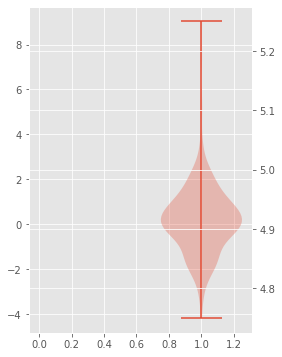

In [32]:
plt.style.use('ggplot')
fig = plt.figure(figsize=(4, 6))
ax1 = fig.add_subplot(111)
ax2 = ax1.twinx()
ax1.violinplot(gene.loc['TCGA-55-7727-01'][get_omics(1, 'gene')].tolist())
ax2.plot(5)
plt.show()

In [37]:
[gene.loc['TCGA-55-7727-01'][['LCK', 'STAT5A']].tolist()] + [gene.loc['TCGA-62-8399-01'][['LCK', 'STAT5A']].tolist()]

[[0.957929496684, -0.403432750683], [0.344129496684, -0.775132750683]]